# 5. Many small fits, fast

*Part 5 of a series on non-negative least squares (NNLS). Previous:
[4. Cholesky and conditioning](04_numerics_cholesky_conditioning.ipynb). This is the last
notebook.*

The first four notebooks were about *one* NNLS fit: what it means, how to recognize the
answer, two ways to find it, and how accurately. This one is about doing it **a few hundred
thousand times in a fraction of a second**, which is what MrFitty's blocked cross-validation
needs, and it's where everything comes together:

- **Trying every support** (notebook 2) has no decisions in it, so it can run the same steps
  on every fit at once.
- **The squeeze** to $G$, $c$ and $s^\top s$ (notebook 2) makes each fit a handful of tiny
  systems.
- **Cholesky** (notebook 4) solves them in a few dozen operations, written out by hand.
- **One condition check per fit** (notebook 4) vouches for every support at once, and the
  **trace bound** does it without calling a library.

There are no new theorems here. This notebook is about engineering, so it measures: three
versions of the same computation, timed live, and checked against SciPy at every step. The
timings are from whatever computer ran this notebook, so yours will differ. The comparisons
between them mostly won't.

In [1]:
%matplotlib inline
import itertools

import numpy as np
import pandas as pd

from nnls_tutorial import batched as B
from nnls_tutorial import many_fits as F
from nnls_tutorial import plotting as P
from nnls_tutorial.data import load_arsenic

P.use_style()
np.set_printoptions(precision=4)

spectra = load_arsenic()
BEST_FIT = [
    "Arsenopyrite_Julcani_OA",
    "orpiment_all_ref_als_cal",
    "arsenate_sorbed_diop_avg_als_cal",
]
best_columns = sorted(spectra.names.index(name) for name in BEST_FIT)  # as the search keys it
R_best = spectra.R[:, best_columns]

## 1. Why so many fits?

Notebook 3 fitted the measured spectrum with all ten references at once, and NNLS switched on
seven of them, some with weights like 0.005. Are those real, or is the fit just using every
reference it's given to chase noise? NNLS can't say. Every reference you add can only lower
the error, so the fit always looks better with more.

Cross-validation asks a fairer question: **does a combination of references predict
energies it wasn't fitted on?** Hide some energies, fit on the rest, and score the fit on the
hidden ones. A combination that only fits noise does well on the energies it saw and badly on
the ones it didn't. Neighboring energies in a spectrum are strongly correlated, so hiding
single energies would be too easy: the fit could predict a hidden energy from its neighbors.
So each **draw** hides a few contiguous *blocks* of energies. Then it's repeated for many
draws, so that no single choice of blocks decides anything.

Here's what the draws look like, with four blocks of ten energies each, about a fifth of the
198:

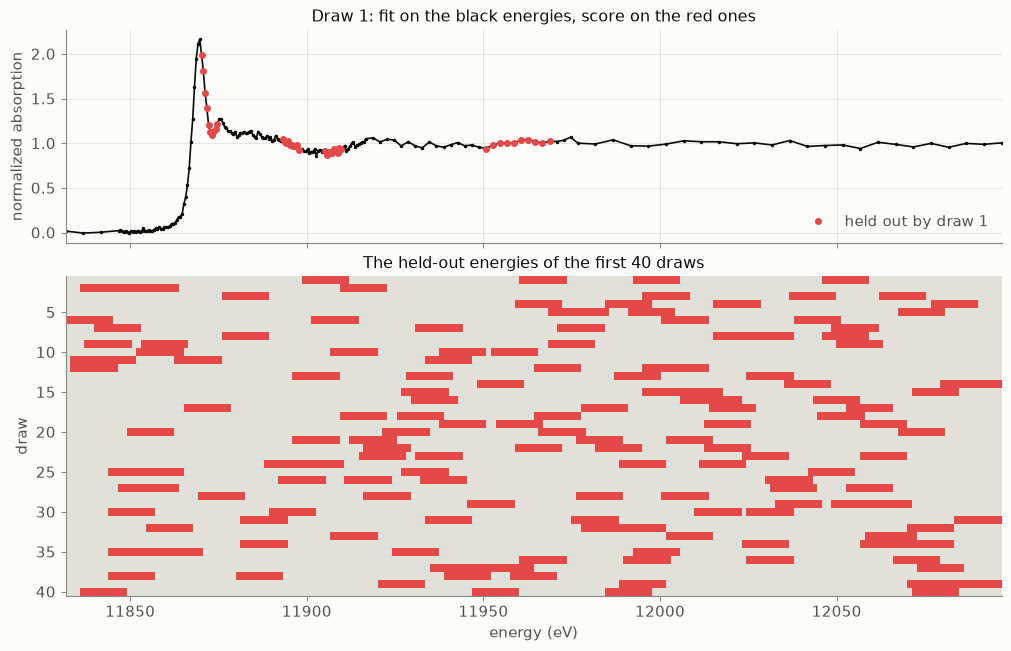

In [2]:
held_out = B.holdout_masks(len(spectra.s), draws=1000)
train = ~held_out
P.show(F.holdout_figure(spectra, held_out))

**Figure 5.1.** Top: the measured spectrum, with the energies that the first draw holds out
in red. Bottom: the held-out energies (red) of the first 40 draws, one row per draw.

Every combination of references is fitted on every draw, and scored by its **prediction
error** on that draw's held-out energies, the root-mean-square difference between the fit
and the measurement there. Here, "every combination" means every choice of one, two or three
of the ten references, 175 of them, so a search is $175 \times 1000 = 175{,}000$ NNLS fits.
MrFitty's real searches are bigger: its reference pool for this sample has 24 references
(Exercise 1), and a search to three references is 2.3 million fits.

(MrFitty's draws also add resampled residuals to the spectrum, a *block bootstrap*, so each
draw's target differs a little too. That changes $c$ and $s^\top s$ from draw to draw, but
nothing about how the fits are solved, so it's left out here.)

All the fits for one combination share $R$ and $s$, and differ only in which rows they use.
So each draw has its own

$$G_j = \sum_{\text{training rows } n} r^{(n)} {r^{(n)}}^\top, \qquad
  c_j = \sum_{\text{training rows } n} s_n\, r^{(n)},$$

where $r^{(n)}$ is row $n$ of $R$, the references' values at one energy.

## 2. Version 0: one SciPy call per fit

The obvious version: loop over the draws, and call `scipy.optimize.nnls` on each one's
training rows. Here it is for every draw of one combination, MrFitty's best fit for this
sample:

In [3]:
W_scipy = B.nnls_scipy_loop(R_best, spectra.s, train)
per_fit = F.seconds(lambda: B.nnls_scipy_loop(R_best, spectra.s, train)) / len(train)
print(f"{per_fit * 1e6:.1f} microseconds per fit")

5.9 microseconds per fit


A few microseconds per fit. That's quick for one fit, but most of it isn't arithmetic: a
fit with three references and 160 energies is a few thousand multiplications, well under a
microsecond's work. The rest is the cost of calling into SciPy from Python, checking the
arguments, and making new arrays, every single time.

## 3. Version 1: batched NumPy

NumPy is fast when one call does a lot of work in compiled code, and slow when Python loops
over many small calls. So the plan is to do each step for **every draw at once**:

1. compute $G_j$, $c_j$ and $s^\top s$ for every draw;
2. check every draw's $\kappa(G_j)$ (notebook 4, Theorem 21);
3. for each support size, solve $G_{PP}\,z = c_P$ for every draw and every support of that
   size, one stack of systems;
4. score every candidate with notebook 2's error shortcut, rule out those with a negative
   weight, and pick each draw's winner.

It's `batched_nnls` in the package, about 40 lines. Getting it fast took three lessons, which
were MrFitty's lessons too.

**Lesson 1: one big matrix product beats a clever `einsum`.** Step 1 is naturally written as
`np.einsum("jn,na,nb->jab", T, R, R)`, where `T` is 1 on training rows and 0 elsewhere. That
works, but NumPy evaluates it with its own loops. The same numbers come from *one matrix
product*: flatten each energy's $m \times m$ table of products $R_{na}R_{nb}$ into a row of
$m^2$ numbers, and multiply `T` by that table (Exercise 2). A matrix product goes to BLAS, the
heavily optimized linear algebra library underneath NumPy.

**Lesson 2: batch the arithmetic, not just the call.** `np.linalg.solve` accepts a stack of
matrices, so step 3 looks like one call. But inside, it hands the matrices to LAPACK one at a
time, and for a $3 \times 3$ system the hand-off costs more than the solve. Writing Cholesky's
steps (notebook 4) as array operations over the whole stack removes the per-matrix cost: the
loops run over the rows of $L$, a handful of times, not over the matrices.

**Lesson 3: compute only what survives.** Each draw keeps one candidate out of $2^m - 1$.
Spreading every candidate's weights out into full-width arrays and then choosing would do
$2^m - 1$ times more copying than needed. So the winners are chosen from the errors first, and
only their weights are gathered.

Here are the first two lessons measured, with five references, so 31 supports:

In [4]:
R_five = spectra.R[:, :5]
G, c, ss = B.gram_blas(R_five, spectra.s, train)
assert np.allclose(G, B.gram_einsum(R_five, spectra.s, train)[0])

supports_of_3 = np.array(list(itertools.combinations(range(5), 3)))  # the 10 supports of size 3
G_P = G[:, supports_of_3[:, :, None], supports_of_3[:, None, :]]  # 1000 draws x 10 supports
c_P = c[:, supports_of_3]
assert np.allclose(B.batched_cholesky_solve(G_P, c_P), np.linalg.solve(G_P, c_P[..., None])[..., 0])

lessons = {
    "Lesson 1: G for every draw": {
        "np.einsum": F.seconds(lambda: B.gram_einsum(R_five, spectra.s, train)),
        "one matrix product": F.seconds(lambda: B.gram_blas(R_five, spectra.s, train)),
    },
    "Lesson 2: 10,000 3x3 solves": {
        "np.linalg.solve": F.seconds(lambda: np.linalg.solve(G_P, c_P[..., None])),
        "batched Cholesky": F.seconds(lambda: B.batched_cholesky_solve(G_P, c_P)),
    },
}

Lesson 4, about compiled code, is measured in Section 4, and Figure 5.2 shows all three
measured lessons together. First, here's the whole batched version on the same thousand draws,
checked against SciPy:

In [5]:
W_batched = B.batched_nnls(R_best, spectra.s, train)
per_fit = F.seconds(lambda: B.batched_nnls(R_best, spectra.s, train)) / len(train)
print(f"{per_fit * 1e6:.2f} microseconds per fit")
print(f"largest difference from SciPy's weights: {np.abs(W_batched - W_scipy).max():.1e}")

1.15 microseconds per fit
largest difference from SciPy's weights: 2.9e-13


Several times faster than the SciPy loop, with the same answers. That's a real gain, but
there's a limit to it. Each step is now one array operation, but there are still a few hundred
of them per combination, each making its own temporary arrays, and every support of every draw
is solved and stored before any are thrown away. NumPy has taken this about as far as it goes.
Going further needs a compiler.

## 4. Version 2: compiled with Numba

[Numba](https://numba.pydata.org/) compiles a subset of Python, plain loops over NumPy
arrays, into machine code. That changes the rules. NumPy's lesson was "no loops in Python",
because each Python-level step is slow. Compiled loops are as fast as C, so the *simplest*
version is now the fast one: **one draw at a time, one support at a time, Cholesky by hand.**

The kernel, `_refit_one` in the package, does this for one draw:

1. Build $G$, $c$ and $s^\top s$ from the training rows, with three nested loops.
2. Factor $G = LL^\top$ and compute the trace bound
   $\operatorname{tr}(G)\,\|L^{-1}\|_F^2$ (notebook 4, Theorem 22). If it's over $10^8$, give up
   and let SciPy refit this draw.
3. For every support, smallest first: factor $G_{PP}$, two triangular solves, and if every
   weight is $\ge 0$, the error shortcut. Keep the best.

No rank checks and no guards on the square roots inside step 3: the check in step 2 already
guarantees every $G_{PP}$ is positive definite (Exercise 3). And no memory is allocated
inside the support loop, so nothing waits on anything else.

Numba spreads the draws across the computer's cores with `prange`, a parallel `range`.
The first call compiles the kernel, which takes a second or two; the package caches the
compiled code on disk, so later runs skip that.

In [6]:
compile_time = F.seconds(lambda: B.compiled_nnls(R_best, spectra.s, train[:2]), repeat=1)
print(f"first call, including compiling: {compile_time:.2f} s")
W_compiled = B.compiled_nnls(R_best, spectra.s, train)
per_fit = F.seconds(lambda: B.compiled_nnls(R_best, spectra.s, train)) / len(train)
print(f"{per_fit * 1e6:.2f} microseconds per fit")
print(f"largest difference from SciPy's weights: {np.abs(W_compiled - W_scipy).max():.1e}")

first call, including compiling: 0.11 s
0.28 microseconds per fit
largest difference from SciPy's weights: 2.9e-13


**Lesson 4: in compiled, parallel code, stay out of LAPACK.** Step 2's check could have used
`np.linalg.eigvalsh`, which Numba supports, to get $\kappa(G)$ exactly. MrFitty's first
compiled version did, and found it took 98% of the time. Each call hands off to LAPACK,
which allocates its own working memory, and many threads doing that at once get in each
other's way. The trace bound is a few dozen multiplications by hand. Here are the two checks
alone, over 50,000 draws with five references:

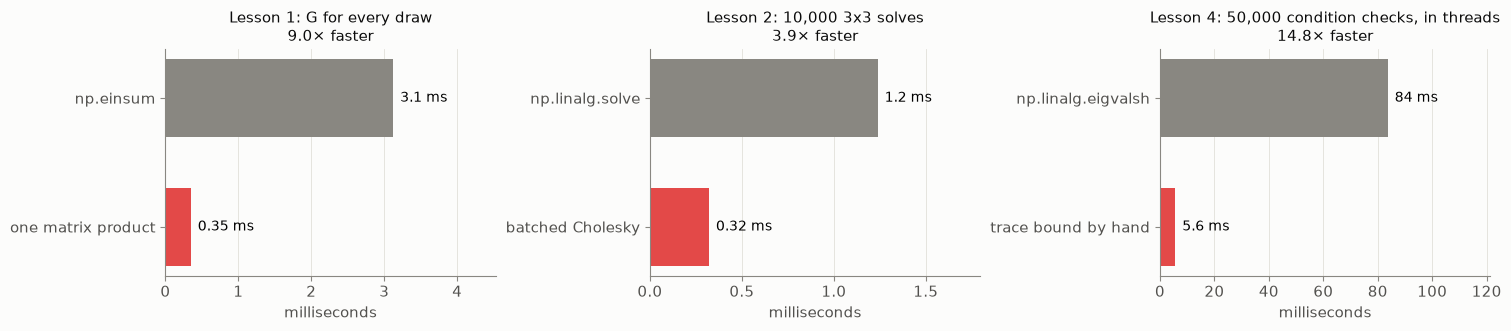

In [7]:
many_draws = ~B.holdout_masks(len(spectra.s), draws=50_000, seed=1)
for method in ["eigvalsh", "trace"]:  # compile both first
    B.condition_checks(R_five, many_draws[:2], method)
lessons["Lesson 4: 50,000 condition checks, in threads"] = {
    "np.linalg.eigvalsh": F.seconds(lambda: B.condition_checks(R_five, many_draws, "eigvalsh")),
    "trace bound by hand": F.seconds(lambda: B.condition_checks(R_five, many_draws, "trace")),
}
P.show(F.lessons_figure(lessons))

**Figure 5.2.** Three of the lessons, each measured on the computer that ran this notebook:
the slow way (gray) against the fast way (red).

**Lesson 5: give each thread a big piece of work.** `compiled_nnls` runs the draws of *one*
combination in parallel, so a search calls it 175 times, and starts the threads 175 times. For
small combinations that start-up costs more than the fits. MrFitty's fix, and
`search_compiled`'s, is to share out the *combinations* among the threads instead, each thread
working through every draw of its combinations in turn. Then the whole search is one call.

## 5. The whole search

Here's the search, every combination of up to three references on all 1000 draws, done four
ways:

In [8]:
fits = 175 * len(train)
timings = {}
results_scipy = B.search(spectra, held_out, solve=B.nnls_scipy_loop)
timings["SciPy, one call per fit"] = F.seconds(
    lambda: B.search(spectra, held_out, solve=B.nnls_scipy_loop), repeat=1
)

In [9]:
timings["batched NumPy"] = F.seconds(lambda: B.search(spectra, held_out, solve=B.batched_nnls))
timings["compiled, one call per combination"] = F.seconds(
    lambda: B.search(spectra, held_out, solve=B.compiled_nnls)
)

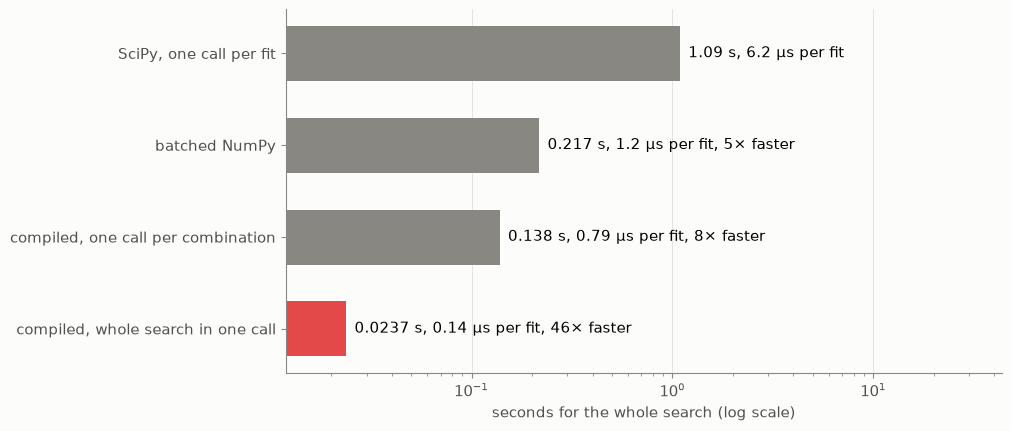

In [10]:
B.search_compiled(spectra, held_out[:2])  # compile
results_fast = B.search_compiled(spectra, held_out)
timings["compiled, whole search in one call"] = F.seconds(
    lambda: B.search_compiled(spectra, held_out)
)
P.show(F.timing_figure(timings, fits))

**Figure 5.3.** Time for the whole search, 175 combinations on 1000 draws each, by each
version, with the time per fit and the speed-up over SciPy. Log scale.

The last version is the one MrFitty runs. At this speed the search is effectively free, and
MrFitty can afford searches to four or five references, millions of fits, in seconds.

## 6. Is it right?

Fast is worthless if it's wrong, so here's the compiled search against SciPy, fit by fit:

largest difference in a weight:           1.2e-10
largest difference in a prediction error: 6.2e-13


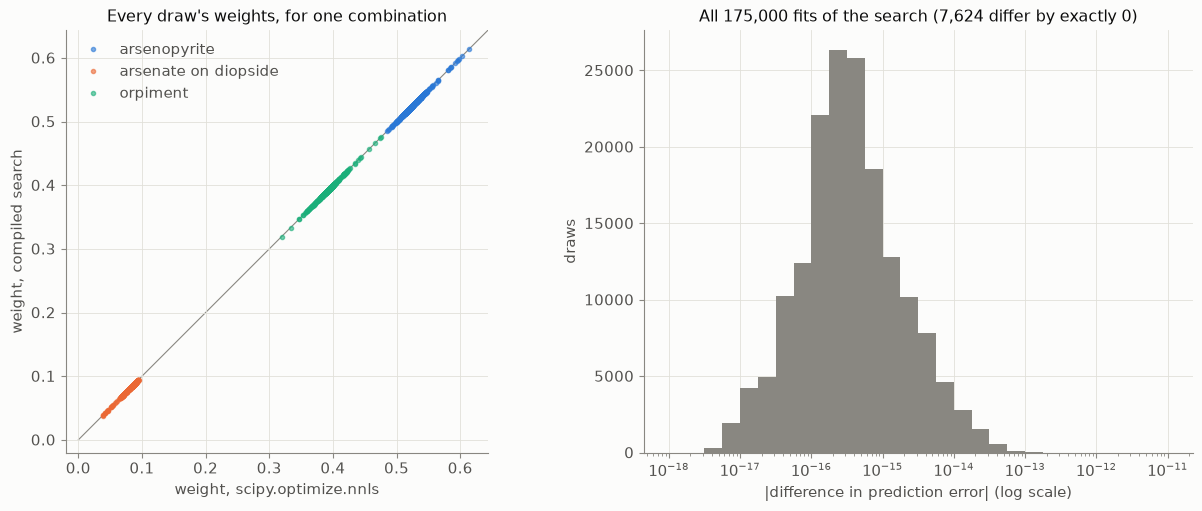

In [11]:
pe_differences = np.concatenate(
    [np.abs(results_fast[combo][1] - results_scipy[combo][1]) for combo in results_scipy]
)
weight_differences = np.concatenate(
    [np.abs(results_fast[combo][0] - results_scipy[combo][0]).ravel() for combo in results_scipy]
)
print(f"largest difference in a weight:           {weight_differences.max():.1e}")
print(f"largest difference in a prediction error: {pe_differences.max():.1e}")
combo = tuple(best_columns)
P.show(
    F.agreement_figure(
        spectra, best_columns, results_scipy[combo][0], results_fast[combo][0], pe_differences
    )
)

**Figure 5.4.** Left: the weights of every draw for MrFitty's best-fit trio, from the compiled
search against SciPy. They lie on the diagonal. Right: the difference in prediction error
between the two, for all 175,000 fits, on a log scale. Some are identical to the last bit
(the count is in the title), and the rest differ by $10^{-17}$ to $10^{-13}$.

The largest weight difference is bigger than the others, about $10^{-10}$. That's notebook 4's
twins at work: combinations that contain both As$_2$O$_3$ and sodium arsenite have
$\kappa(G) \approx 10^5$, and the normal equations lose about five digits on them.

What matters in the end is the decision the search makes: which combination predicts best.
Here are the top few by median prediction error over the draws, both ways:

In [12]:
def ranking(results):
    """Combinations by median prediction error; exact ties go to the smaller combination."""
    median = {combo: round(float(np.median(pe)), 12) for combo, (_, pe) in results.items()}
    return sorted(median, key=lambda combo: (median[combo], len(combo), combo)), median


order_scipy, median_scipy = ranking(results_scipy)
order_fast, median_fast = ranking(results_fast)
print("the same ranking, all 175 combinations:", order_scipy == order_fast)
pd.DataFrame(
    {
        "combination": [", ".join(spectra.labels[i] for i in combo) for combo in order_fast[:6]],
        "median prediction error (compiled)": [median_fast[combo] for combo in order_fast[:6]],
        "median prediction error (SciPy)": [median_scipy[combo] for combo in order_fast[:6]],
    }
)

the same ranking, all 175 combinations: True


,combination,median prediction error (compiled),median prediction error (SciPy)
0,"arsenopyrite, orpiment, scorodite",0.029216,0.029216
1,"arsenopyrite, arsenate on diopside, orpiment",0.029527,0.029527
2,"arsenopyrite, aqueous arsenite, orpiment",0.031722,0.031722
3,"arsenopyrite, orpiment, sodium arsenate",0.031963,0.031963
4,"arsenopyrite, orpiment, sodium arsenite",0.032153,0.032153
5,"arsenopyrite, As$_2$O$_3$, orpiment",0.032216,0.032216


The two rankings are identical, once one detail is handled. Many combinations tie exactly: a
trio whose third reference is switched off on *every* draw makes exactly the same fits as the
pair without it, so it has the same prediction errors. The compiled search gets those ties
bit-for-bit equal. SciPy, which takes a different route to the same answer, can differ in
the 16th digit, and that's enough to swap tied combinations in a sort. So the ranking rounds
to 12 digits and breaks ties toward the smaller combination, which is the sensible choice
anyway: if a reference never gets used, leave it out. (MrFitty has a more careful tie rule,
which asks whether two combinations' prediction errors differ by more than chance.)

One caution about the answer itself. This notebook's cross-validation is simplified (no
block bootstrap, and the simplest scoring), and it ranks arsenopyrite, orpiment and scorodite
first, with MrFitty's choice, arsenate on diopside in place of scorodite, a very close second.
Choosing between those two is a statistics question. MrFitty's notebook is about exactly
that, and it's beyond this series. What this series can promise is that every one of the
175,000 fits behind the ranking is the exact NNLS answer.

## Exercises

**1.** *How big is the pool?* A search to three references has $\binom{p}{1} + \binom{p}{2} +
\binom{p}{3}$ combinations for a pool of $p$ references. MrFitty's search for this sample
has 2,324. Find $p$. With 1000 draws, how long would that search take at the per-fit times
in Figure 5.3, SciPy's and the fastest?

<details><summary>Solution</summary>

$p = 24$: $24 + 276 + 2024 = 2324$. That's 2,324,000 fits. At this notebook's SciPy rate,
several microseconds per fit, it's around 15 seconds; at the compiled search's rate, a
fraction of a microsecond, it's well under a second. A search to five references from 24 is
$\binom{24}{4} + \binom{24}{5} = 10{,}626 + 42{,}504$ more combinations, each with up to 31
supports, and that's where the difference starts to matter.
</details>

**2.** *One matrix product.* Show that if $T$ is the $k \times n$ matrix of training masks and
$O$ is the $n \times m^2$ matrix whose row $n$ lists the products $R_{na}R_{nb}$ for all $a, b$,
then row $j$ of $TO$, read as an $m \times m$ matrix, is $G_j$. Count the multiplications. Is
the matrix product doing less arithmetic than the `einsum`?

<details><summary>Solution</summary>

$(TO)_{j,(a,b)} = \sum_n T_{jn} O_{n,(a,b)} = \sum_n T_{jn} R_{na} R_{nb} = (G_j)_{ab}$, since
$T_{jn}$ is 1 exactly on draw $j$'s training rows. It takes $k \cdot n \cdot m^2$
multiplications, plus $n m^2$ to build $O$. The `einsum` does the same sums, at least
$k \cdot n \cdot m^2$ multiplications. So it's not less arithmetic. It's the *same* arithmetic,
done by BLAS, which arranges it to suit the processor's caches and vector instructions.
</details>

**3.** *Why no guards?* The compiled kernel takes square roots and divides by $L_{jj}$ inside
the support loop without checking anything. Explain why that's safe once the draw has passed
the trace-bound check.

<details><summary>Solution</summary>

Passing the check means $L$ for the whole $G$ was computed with positive pivots, so $G$ is
positive definite, and $\kappa(G) \le \operatorname{tr}(G)\operatorname{tr}(G^{-1}) \le 10^8$
(Theorem 22). By Theorem 21, every $G_{PP}$ has its smallest eigenvalue at least $G$'s, so
it's positive definite too, and by Theorem 19, Cholesky's numbers under the square roots are
all positive. With $\kappa(G_{PP}) \le 10^8$, rounding loses at most about 8 digits, which
can't turn a positive pivot negative. So there's nothing to guard against. Compare notebook
4's Exercise 4, where a duplicate column broke Cholesky: that $G$ would fail the check.
</details>

**4.** *Tighten the limit.* Run the compiled search with `condition_limit=1e5` and find which
combinations have draws sent to SciPy. Explain the list using notebook 4.

<details><summary>Solution</summary>

```python
combos = B.combinations_up_to(10, 3)
padded = np.full((len(combos), 3), -1)
for ci, combo in enumerate(combos):
    padded[ci, : len(combo)] = combo
sizes = np.array([len(combo) for combo in combos])
_, _, passed = B._search_compiled(
    np.ascontiguousarray(spectra.R), spectra.s, held_out, padded, sizes,
    B.support_masks(3), 1e5,
)
for ci in np.flatnonzero(~passed.all(axis=1)):
    print([spectra.labels[i] for i in combos[ci]], (~passed[ci]).sum(), "draws")
```

Exactly nine combinations: the twins as a pair, and the twins with each of the other eight
references. Every draw of the trios fails, and about three quarters of the pair's draws do.
Notebook 4 found $\kappa(G) \approx 1.2 \times 10^5$ for the twins on all 198 energies; each
draw uses a slightly different subset of energies, so the pair's $\kappa$ varies around the
limit from draw to draw, and adding a third reference can only raise it (Theorem 21).
</details>

## Summary

- Cross-validation turns one fit into **hundreds of thousands**: every combination of
  references, on every draw of held-out energy blocks.
- **SciPy in a loop** spends most of its time on the call, not the arithmetic.
- **Batched NumPy** does each step for every draw at once. It needs one BLAS product for the
  $G_j$, Cholesky written over the whole stack, and only the winners copied out.
- **Compiled Numba** makes the simplest version the fastest: plain loops, one draw and one
  support at a time, Cholesky by hand, the **trace bound** instead of LAPACK, and whole
  combinations shared among the threads.
- At every step, the answers match SciPy's, and the search's decisions are the same.

That's the series. Starting from a negative weight that made no physical sense, it built up
the geometry of NNLS (notebook 1), its optimality conditions and the exactness of trying every
support (notebook 2), the classic active-set algorithm (notebook 3), the numerics of the small
systems inside both (notebook 4), and finally the fast solver MrFitty uses (this notebook).